# Theory notes

Working notes on the two reference papers and on the numerical choices made in
this repository. Formulas use the conventions of the code.

Every section keeps the text of the original notes and adds small experiments
that make the idea visible: a picture of the kernel, a few simulated paths, a
smile that moves when a parameter moves. The heavy lifting is done by the
package in `src/rbergomi_nn`; the code here only calls it and plots.

> Run with the project environment (`pip install -e .`), from the repository
> root or from `docs/`. The whole notebook runs in about a minute on a laptop.

In [1]:
import time
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch

from rbergomi_nn.black_scholes import implied_vol
from rbergomi_nn.calibration import calibrate, network_pricer
from rbergomi_nn.dataset import HURST_GAP, TRAIN_BOX
from rbergomi_nn.network import VolSurfaceMLP
from rbergomi_nn.pricing import mixed_estimator, standard_estimator
from rbergomi_nn.simulator import (
    DTYPE, RBergomiParams, hybrid_scheme_weights, simulate_spot, simulate_variance, simulate_volterra,
)
from rbergomi_nn.surface import MonteCarloConfig, SurfaceGrid, implied_vol_surface

ROOT = Path.cwd().parent if Path.cwd().name == "docs" else Path.cwd()

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
})


def gen(seed: int) -> torch.Generator:
    # A fixed seed per experiment, so that every figure is reproducible.
    return torch.Generator().manual_seed(seed)


def t(x) -> torch.Tensor:
    return torch.as_tensor(x, dtype=DTYPE)


# Reference parameters used throughout: a typical rough Bergomi fit, inside the training box.
BASE = RBergomiParams(hurst=0.1, eta=1.9, rho=-0.7, xi0=0.04)

## 1. Rough Bergomi

### Why rough volatility

Two empirical facts motivate the model:

* **Realised volatility is "rough":** in real markets, log-volatility behaves like a fractional
  Brownian motion with Hurst exponent $H ≈ 0.1$, far rougher than the $H = 1/2$ of a diffusion.
  The idea is that recent shocks weight more than the old ones, while in standard Brownian
  motion ($H=1/2$) they weight the same.
* **The ATM skew explodes at short maturities:** on SPX the skew
  $\psi(T) = |\partial_k \sigma_{BS}(k = 0, T)|$ follows a power law $T^{-0.4}$, roughly.
  Classical stochastic volatility models give a skew that is flat as $T \rightarrow 0$;
  they can only fit the short end by adding jumps or many factors.

A model driven by a fractional kernel with exponent $H − 1/2$ produces a skew
of order $T^{H − 1/2}$: *one parameter explains both facts*.

**Picture 1: how much a past shock counts today.** The rough process is a weighted sum of past
Brownian shocks, $Y_t = \int_0^t (t-s)^{H-1/2}\,dW_s$. The weight depends only on the *age*
$t-s$ of the shock. For $H = 1/2$ it is constant (every shock counts the same: plain Brownian
motion); for small $H$ it is huge for the most recent shocks and decays quickly.

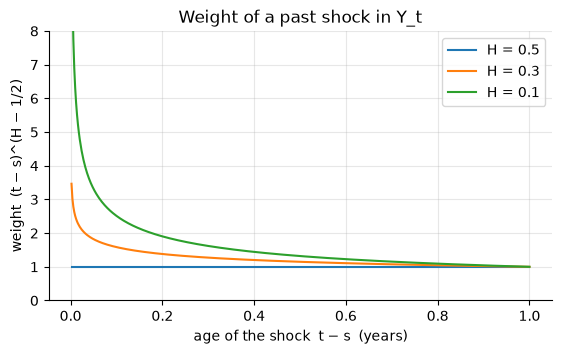

In [2]:
age = np.linspace(0.002, 1.0, 500)  # t - s, in years

fig, ax = plt.subplots(figsize=(6.5, 3.5))
for H in (0.5, 0.3, 0.1):
    ax.plot(age, age ** (H - 0.5), label=f"H = {H}")
ax.set(xlabel="age of the shock  t − s  (years)", ylabel="weight  (t − s)^(H − 1/2)",
       ylim=(0, 8), title="Weight of a past shock in Y_t")
ax.legend()
plt.show()

**Picture 2: what "rough" looks like.** The same Brownian shocks fed through the three kernels.
$\sqrt{2H}\,Y_t$ has variance $t^{2H}$ for every $H$, so the paths have comparable size: only
their texture changes. With $H = 0.1$ the path is much more jagged than a Brownian motion.

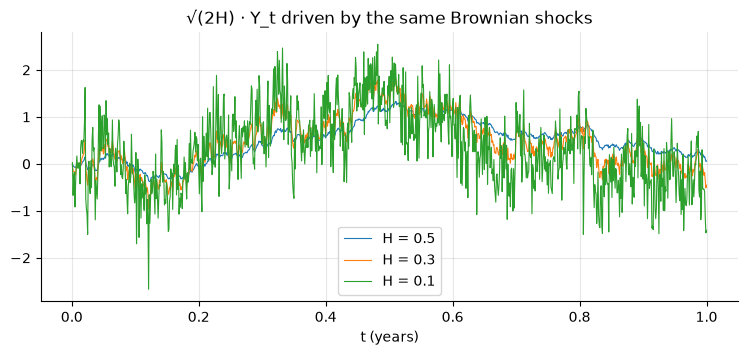

In [3]:
n_steps, dt = 1000, 1 / 1000
times = dt * np.arange(1, n_steps + 1)

fig, ax = plt.subplots(figsize=(9, 3.5))
for H in (0.5, 0.3, 0.1):
    # same seed -> same Brownian increments, only the kernel changes
    _, Y = simulate_volterra(t(H), n_steps, dt, n_paths=1, generator=gen(1), antithetic=False)
    ax.plot(times, np.sqrt(2 * H) * Y[0].numpy(), lw=0.8, label=f"H = {H}")
ax.set(xlabel="t (years)", title="√(2H) · Y_t driven by the same Brownian shocks")
ax.legend()
plt.show()

**Picture 3: the skew power law.** A skew of order $T^{H-1/2}$ is flat for $H = 1/2$ and blows
up at short maturities for $H < 1/2$. With $H \approx 0.1$ the exponent is $-0.4$, the value
observed on SPX. (Shapes only, normalised to 1 at $T = 1$; the simulated skew is checked
against this law in *Checks available without a closed formula* below.)

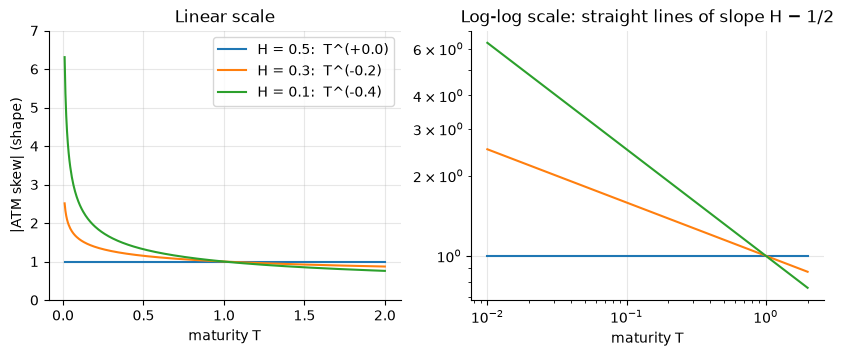

In [4]:
maturity = np.linspace(0.01, 2.0, 400)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for H in (0.5, 0.3, 0.1):
    for ax in axes:
        ax.plot(maturity, maturity ** (H - 0.5), label=f"H = {H}:  T^({H - 0.5:+.1f})")
axes[0].set(xlabel="maturity T", ylabel="|ATM skew| (shape)", title="Linear scale", ylim=(0, 7))
axes[1].set(xlabel="maturity T", title="Log-log scale: straight lines of slope H − 1/2",
            xscale="log", yscale="log")
axes[0].legend()
plt.show()

### The model

Under the pricing measure, with zero rates:

$$
\begin{aligned}
\frac{dS_t}{S_t} &= \sqrt{v_t}\,dZ_t, \\
v_t &= \xi_0(t)\,\exp\!\Big(\eta\sqrt{2H}\,Y_t - \tfrac{\eta^2}{2}\,t^{2H}\Big), \\
Y_t &= \int_0^t (t-s)^{H-\frac12}\,dW_s, \\
Z_t &= \rho\,W_t + \sqrt{1-\rho^2}\,W_t^{\perp},
\end{aligned}
$$

The rBergomi model has **4 parameters**:

| Parameter | Role | Effect on the surface |
|---|---|---|
| $H \in (0, 1/2]$ | roughness of the variance paths | how fast the skew decays with maturity |
| $\eta > 0$ | volatility of variance | smile curvature and overall skew size |
| $\rho \in  [−1, 1]$ | spot–variance correlation | sign and size of the skew |
| $\xi_0(t)$ | forward variance curve, $\xi_0(t) = E[v_t]$ | level (here flat: a single number) |

$\sqrt{2H} \cdot Y_t$ is a **Riemann–Liouville fractional Brownian motion** with
variance $t^{2H}$, so the exponential is a martingale in $\eta$ and $E[v_t] = \xi_0(t)$:
the model is consistent with the variance swap curve by construction. Bayer,
Friz and Gatheral fit SPX smiles with just three numbers, typically
$H ≈ 0.07$, $\eta ≈ 1.9$, $\rho ≈ −0.9$.

**Simulated paths.** A few volatility paths $\sqrt{v_t}$ and the corresponding spot paths.
With $\rho < 0$ the spot tends to fall when volatility spikes: this is the leverage effect
that produces the negative skew.

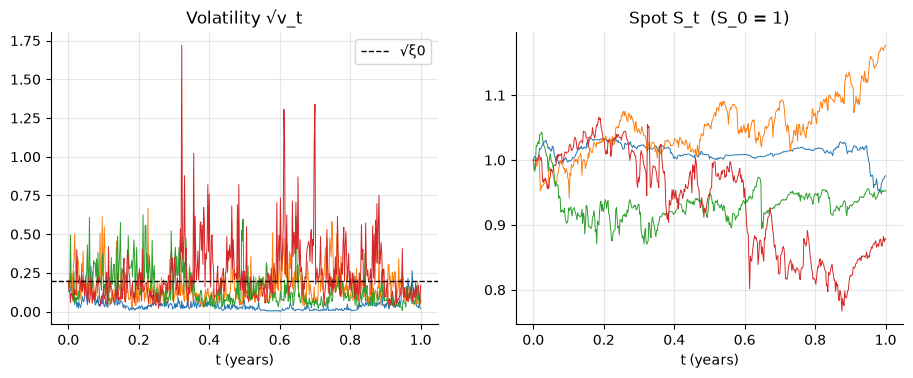

In [ ]:
steps_per_year = 500 
horizon = 1.0 
n_paths = 20_000
paths = simulate_variance(BASE, n_steps=int(horizon * steps_per_year), dt=1 / steps_per_year,
                          n_paths=n_paths, generator=gen(2))
spot = simulate_spot(paths, BASE.rho, generator=gen(3))
times = paths.times.numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for i in range(4):
    axes[0].plot(times, np.sqrt(paths.variance[i].numpy()), lw=0.7)
    axes[1].plot(times, spot[i].numpy(), lw=0.7)
axes[0].axhline(np.sqrt(BASE.xi0), color="k", ls="--", lw=1, label="√ξ0")
axes[0].set(title="Volatility √v_t", xlabel="t (years)")
axes[1].set(title="Spot S_t  (S_0 = 1)", xlabel="t (years)")
axes[0].legend()
plt.show()

**One parameter at a time.** Each panel moves one parameter around `BASE` and shows the smile
(implied volatility against log-moneyness $k = \log(K/S_0)$) at a short maturity (solid) and a
long one (dashed). This is the table above, made visible.

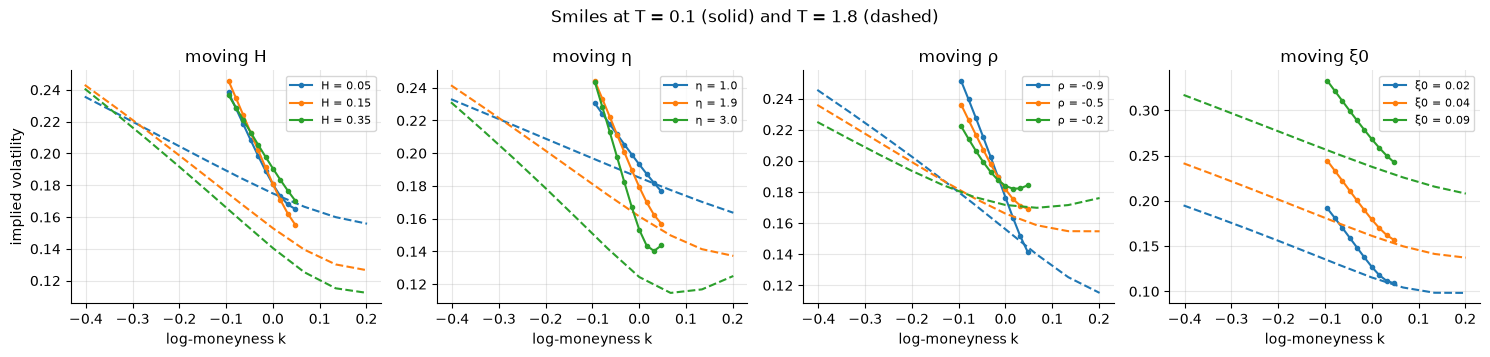

In [6]:
grid = SurfaceGrid()                       # the 8 x 10 grid used by the network
mc = MonteCarloConfig(n_paths=8192)        # fewer paths than the dataset: enough for a picture
short, long = 0, 6                         # indices of T = 0.1 and T = 1.8 in the grid
variations = {
    "hurst": (0.05, 0.15, 0.35),
    "eta": (1.0, 1.9, 3.0),
    "rho": (-0.9, -0.5, -0.2),
    "xi0": (0.02, 0.04, 0.09),
}
labels = {"hurst": "H", "eta": "η", "rho": "ρ", "xi0": "ξ0"}
log_k = grid.log_moneyness.numpy()

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=False)
for ax, (name, values) in zip(axes, variations.items()):
    for value, colour in zip(values, ("tab:blue", "tab:orange", "tab:green")):
        vol = implied_vol_surface(replace(BASE, **{name: value}), grid, mc, seed=4).implied_vol
        ax.plot(log_k[short], vol[short], "-o", ms=3, color=colour, label=f"{labels[name]} = {value}")
        ax.plot(log_k[long], vol[long], "--", color=colour)
    ax.set(title=f"moving {labels[name]}", xlabel="log-moneyness k")
    ax.legend(fontsize=8)
axes[0].set_ylabel("implied volatility")
fig.suptitle(f"Smiles at T = {grid.maturities[short]} (solid) and T = {grid.maturities[long]} (dashed)")
fig.tight_layout()
plt.show()

### Why it is expensive

$Y$ is not a semimartingale and not Markovian: $v_t$ depends on the whole past
of $W$. There is no PDE, no characteristic function, no closed formula! Prices
come from Monte Carlo, and a calibration needs hundreds of them. This is the
bottleneck the neural network removes, but can it be fully trusted?

How long does one surface take with the settings used for the training data?

In [7]:
start = time.perf_counter()
mc_surface = implied_vol_surface(BASE, grid, MonteCarloConfig(), seed=0)
mc_seconds = time.perf_counter() - start

print(f"one Monte Carlo surface ({MonteCarloConfig().n_paths} paths, {grid.size} options): {mc_seconds:.2f} s")
print(f"a calibration with ~300 surface evaluations:            ~{300 * mc_seconds / 60:.1f} min")

one Monte Carlo surface (16384 paths, 80 options): 0.53 s
a calibration with ~300 surface evaluations:            ~2.6 min


### Simulation: the hybrid scheme (Bennedsen, Lunde, Pakkanen 2017)

[*DISCLAIMER: the Monte Carlo simulations section has been completely managed by Claude Code Fable 5.2*]

A plain Riemann sum for $Y$ fails because the kernel $(t − s)^{H − 1/2}$ blows
up at $s = t$. The hybrid scheme splits the integral on a grid of step $\Delta$:

$$
Y_{t_i} \approx
\underbrace{\int_{t_{i-1}}^{t_i} (t_i - s)^{\alpha}\,dW_s}_{\text{exact, where the kernel is singular}}
\;+\;
\underbrace{\sum_{k=2}^{i} (b_k \Delta)^{\alpha}\,\big(W_{t_{i-k+1}} - W_{t_{i-k}}\big)}_{\text{step function elsewhere}}
$$

with $\alpha = H − 1/2$ and the optimal evaluation points

$$
b_k^{\alpha} = \frac{k^{\alpha+1} - (k-1)^{\alpha+1}}{\alpha+1},
$$

the average of the kernel over each cell.

Time is measured backwards from $t_i$ in units of $\Delta$.
The kernel (black) is infinite at lag 0. The hybrid scheme handles the first cell exactly and
replaces the kernel by its *average* over each further cell (blue). A Riemann sum uses the value
at one end of each cell instead (red): it misses the mass near the singularity.

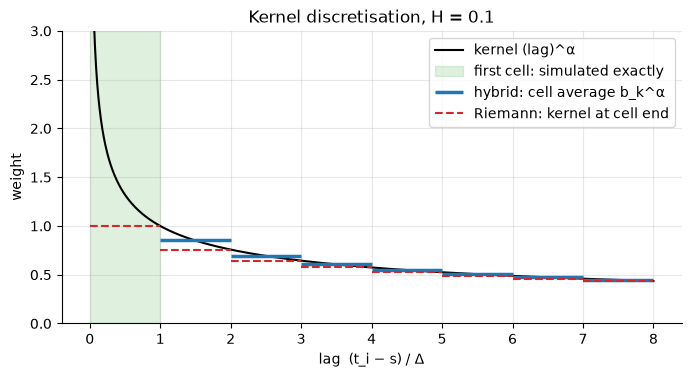

In [8]:
H = 0.1
alpha = H - 0.5
lags = np.arange(1, 9)                                                  # cell k covers lag in [k-1, k]
hybrid = (lags ** (alpha + 1) - (lags - 1) ** (alpha + 1)) / (alpha + 1)  # b_k^alpha, cell average
riemann = lags.astype(float) ** alpha                                    # kernel at the far end of the cell

x = np.linspace(1e-3, 8, 2000)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(x, x ** alpha, "k", lw=1.5, label="kernel (lag)^α")
ax.axvspan(0, 1, color="tab:green", alpha=0.15, label="first cell: simulated exactly")
for k in lags[1:]:
    ax.hlines(hybrid[k - 1], k - 1, k, color="tab:blue", lw=2.5,
              label="hybrid: cell average b_k^α" if k == 2 else None)
    ax.hlines(riemann[k - 1], k - 1, k, color="tab:red", lw=1.5, ls="--",
              label="Riemann: kernel at cell end" if k == 2 else None)
ax.hlines(riemann[0], 0, 1, color="tab:red", lw=1.5, ls="--")
ax.set(xlabel="lag  (t_i − s) / Δ", ylabel="weight", ylim=(0, 3), title=f"Kernel discretisation, H = {H}")
ax.legend()
plt.show()

Both approximations are sums of independent Gaussian increments, so
their variance can be computed exactly, without simulating, and compared with the true
$\operatorname{Var}(Y_1) = 1/(2H)$. The Riemann sum converges very slowly when $H$ is small;
the hybrid scheme is accurate already with a handful of steps.

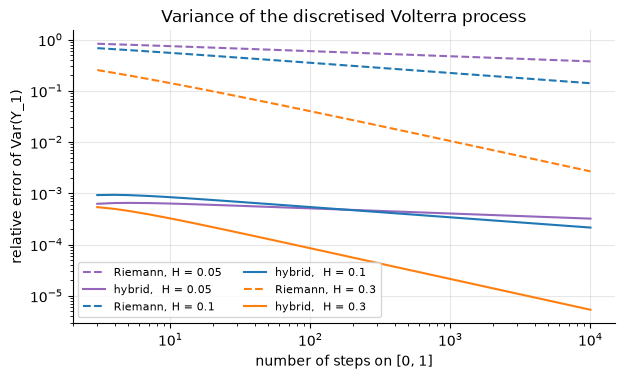

In [9]:
def variance_riemann(H, n):
    # Y_1 ≈ Σ_{k=1}^{n} (kΔ)^α ΔW,  with Δ = 1/n
    alpha, dt, k = H - 0.5, 1 / n, np.arange(1, n + 1)
    return np.sum((k * dt) ** (2 * alpha) * dt)


def variance_hybrid(H, n):
    # exact first cell + step function with weights (b_k Δ)^α further back
    alpha, dt, k = H - 0.5, 1 / n, np.arange(2, n + 1)
    b_alpha = (k ** (alpha + 1) - (k - 1) ** (alpha + 1)) / (alpha + 1)
    return dt ** (2 * alpha + 1) / (2 * alpha + 1) + np.sum((b_alpha * dt ** alpha) ** 2 * dt)


n_values = np.unique(np.logspace(0.5, 4, 30).astype(int))
fig, ax = plt.subplots(figsize=(7, 3.8))
for H, colour in ((0.05, "tab:purple"), (0.1, "tab:blue"), (0.3, "tab:orange")):
    exact = 1 / (2 * H)
    ax.loglog(n_values, [abs(variance_riemann(H, n) / exact - 1) for n in n_values], "--", color=colour,
              label=f"Riemann, H = {H}")
    ax.loglog(n_values, [abs(variance_hybrid(H, n) / exact - 1) for n in n_values], "-", color=colour,
              label=f"hybrid,  H = {H}")
ax.set(xlabel="number of steps on [0, 1]", ylabel="relative error of Var(Y_1)",
       title="Variance of the discretised Volterra process")
ax.legend(fontsize=8, ncol=2)
plt.show()

The first term and the Brownian increment over the same step are jointly
Gaussian with covariance

$$
\operatorname{Var}(\Delta W) = \Delta, \qquad
\operatorname{Cov} = \frac{\Delta^{\alpha+1}}{\alpha+1}, \qquad
\operatorname{Var}(\text{local}) = \frac{\Delta^{2\alpha+1}}{2\alpha+1}
$$

so they are sampled exactly from two independent normals. In code this is just a $2\times 2$
Cholesky factor applied to two standard normals:

In [10]:
H, dt = 0.1, 1 / 200
alpha = H - 0.5
covariance = np.array([
    [dt,                             dt ** (alpha + 1) / (alpha + 1)],
    [dt ** (alpha + 1) / (alpha + 1), dt ** (2 * alpha + 1) / (2 * alpha + 1)],
])
L = np.linalg.cholesky(covariance)
z = np.random.default_rng(0).standard_normal((2, 1_000_000))   # two independent normals
dW, local = L @ z                                              # correlated pair (ΔW, local term)

print("target covariance:\n", covariance)
print("sample covariance:\n", np.cov(dW, local))
print(f"correlation: {np.corrcoef(dW, local)[0, 1]:.3f}")

target covariance:
 [[0.005      0.06937943]
 [0.06937943 1.73286211]]
sample covariance:
 [[0.00500673 0.06946003]
 [0.06946003 1.7322367 ]]
correlation: 0.746


The second term is a
discrete convolution of past increments with fixed weights, implemented as one
matrix product. For $H = 1/2$ every weight is one and $Y = W$ exactly, which
gives a path-by-path unit test.

The weight matrix is upper triangular with a zero first super-diagonal (the lag-1 cell is the
exact local term). Each column is the kernel seen from one time point:

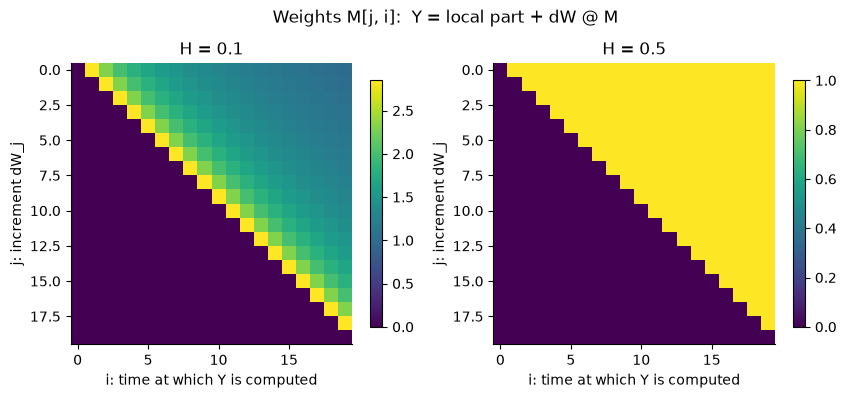

H = 1/2:  max |Y - W| = 5.551115123125783e-16


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, H in zip(axes, (0.1, 0.5)):
    weights = hybrid_scheme_weights(t(H - 0.5), n_steps=20, dt=1 / 20).numpy()
    image = ax.imshow(weights, cmap="viridis")
    ax.set(title=f"H = {H}", xlabel="i: time at which Y is computed", ylabel="j: increment dW_j")
    ax.grid(False)
    fig.colorbar(image, ax=ax, shrink=0.8)
fig.suptitle("Weights M[j, i]:  Y = local part + dW @ M")
plt.show()

# The H = 1/2 unit test: Y must coincide with W path by path.
dW, Y = simulate_volterra(t(0.5), n_steps=100, dt=0.01, n_paths=4, generator=gen(0))
print("H = 1/2:  max |Y - W| =", torch.max(torch.abs(Y - dW.cumsum(dim=1))).item())

The spot is then advanced by log-Euler. The whole simulator is written with
differentiable PyTorch operations, so pathwise sensitivities with respect to
$(H, \eta, \rho, \xi_0)$ are available by automatic differentiation (phase 2).

For example, the sensitivity of the one-year ATM call to $\eta$, by automatic differentiation
and by a finite difference on the same random numbers:

In [12]:
def atm_price(eta):
    params = replace(BASE, eta=eta)
    paths = simulate_variance(params, n_steps=100, dt=0.01, n_paths=8192, generator=gen(5))
    return mixed_estimator(paths, params.rho, maturities=t([1.0]), strikes=t([1.0])).price.squeeze()


eta = t(1.9).requires_grad_(True)
atm_price(eta).backward()

bump = 1e-4
finite_difference = (atm_price(t(1.9 + bump)) - atm_price(t(1.9 - bump))) / (2 * bump)
print(f"d price / d eta   autodiff: {eta.grad.item():.6f}   finite difference: {finite_difference.item():.6f}")

d price / d eta   autodiff: -0.010832   finite difference: -0.010832


### Variance reduction: the mixed estimator

Conditionally on $W$, the variance path is known and $S_T$ is lognormal. The
noise $W^{\perp}$ can therefore be integrated out analytically (Romano–Touzi; used for
rough Bergomi by McCrickerd and Pakkanen 2018):

$$
\text{price} = E\Big[\,\text{Black}\big(S_0\, e^{\rho I_T - \frac{\rho^2}{2} V_T},\; K,\; \sqrt{(1-\rho^2)\,V_T}\big)\Big],
\qquad
I_T = \int_0^T \sqrt{v_t}\,dW_t, \qquad V_T = \int_0^T v_t\,dt
$$

Three consequences matter here: the variance is lower, no spot path has to be
simulated, and the estimate is a smooth, strictly positive function of the
strike, so the implied volatility always exists. On top of this the code uses
antithetic paths and the conditional forward $S_0\, e^{\rho I_T − \rho^2 V_T/2}$,
whose mean is exactly $S_0$, as a control variate.

**Same paths, three estimators.** Out-of-the-money options at $T = 0.5$, priced from the same
4,096 variance paths. Left: the standard error of the price. Right: the implied volatilities.
The standard estimator averages payoffs that are mostly zero in the wings, so its prices are
noisy and the deepest ones have no implied volatility at all (missing points).

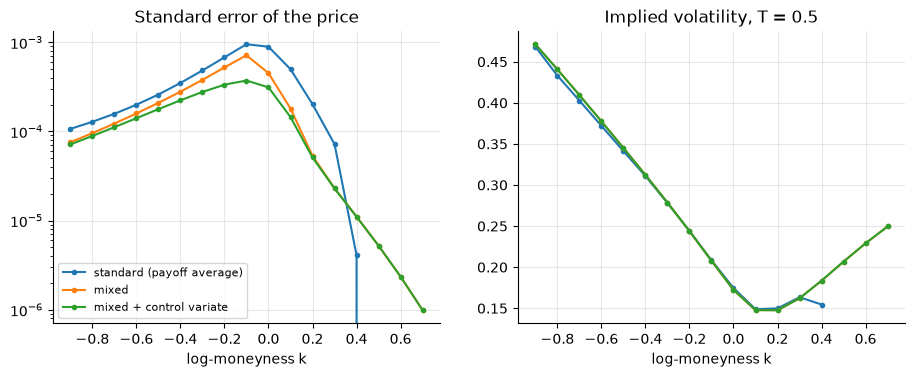

standard (payoff average)   options without an implied vol: 3 / 17
mixed                       options without an implied vol: 0 / 17
mixed + control variate     options without an implied vol: 0 / 17
near the money the standard error is 2.9x smaller: 8x fewer paths for the same accuracy


In [13]:
maturity, n_paths = 0.5, 4096
log_strikes = np.linspace(-0.9, 0.7, 17)
strikes = t(np.exp(log_strikes))

paths = simulate_variance(BASE, n_steps=100, dt=maturity / 100, n_paths=n_paths, generator=gen(6))
spot_paths = simulate_spot(paths, BASE.rho, generator=gen(7))
estimates = {
    "standard (payoff average)": standard_estimator(spot_paths, paths, t([maturity]), strikes),
    "mixed": mixed_estimator(paths, BASE.rho, t([maturity]), strikes, control_variate=False),
    "mixed + control variate": mixed_estimator(paths, BASE.rho, t([maturity]), strikes),
}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, estimate in estimates.items():
    vols = implied_vol(estimate.price[0], t(1.0), strikes, t(maturity), is_call=strikes >= 1.0)
    axes[0].semilogy(log_strikes, estimate.stderr[0], "-o", ms=3, label=name)
    axes[1].plot(log_strikes, vols, "-o", ms=3, label=name)
axes[0].set(title="Standard error of the price", xlabel="log-moneyness k")
axes[1].set(title=f"Implied volatility, T = {maturity}", xlabel="log-moneyness k")
axes[0].legend(fontsize=8)
plt.show()

for name, estimate in estimates.items():
    vols = implied_vol(estimate.price[0], t(1.0), strikes, t(maturity), is_call=strikes >= 1.0)
    print(f"{name:<27} options without an implied vol: {int(torch.isnan(vols).sum())} / {len(log_strikes)}")
atm = np.argmin(np.abs(log_strikes))
ratio = (estimates["standard (payoff average)"].stderr[0, atm] / estimates["mixed + control variate"].stderr[0, atm]).item()
print(f"near the money the standard error is {ratio:.1f}x smaller: {ratio ** 2:.0f}x fewer paths for the same accuracy")

### Checks available without a closed formula

* $E[S_t] = S_0$ and $E[v_t] = \xi_0$ for all $t$.
* $\eta = 0$ is Black–Scholes; $H = 1/2$ makes $Y$ a Brownian motion.
* Published Monte Carlo prices (Bayer, Ben Hammouda, Tempone 2020, Table 5.1).
* The short-maturity skew (Alòs, León, Vives 2007; Fukasawa 2017):

  $$
  \partial_k \sigma_{BS}(0, T) \approx \frac{\rho\,\eta\,\sqrt{2H}}{2\,(H + 1/2)(H + 3/2)}\; T^{H − 1/2}
  $$

  which reduces to $\rho\eta/4$ for $H = 1/2$, the known skew of a lognormal
  stochastic volatility model whose variance has volatility $\eta$.

The full versions of these checks are in `scripts/01_validate_simulator.py`; lighter versions
follow.

**Martingale checks**, on the 20,000 paths simulated above. The band is ± 2 standard errors.

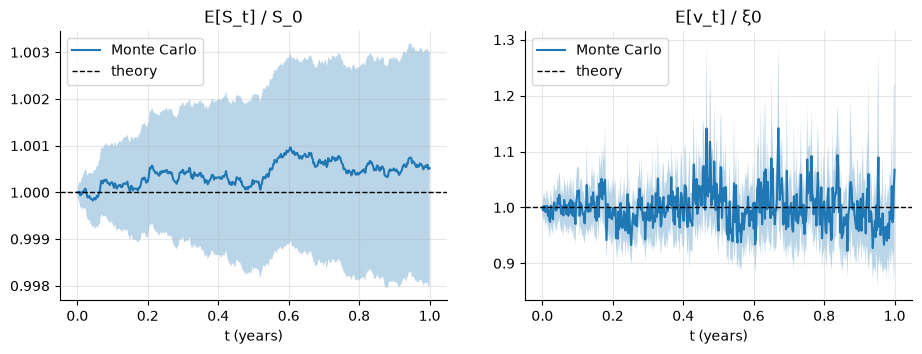

In [14]:
paths = simulate_variance(BASE, n_steps=500, dt=1 / 500, n_paths=20_000, generator=gen(2))
spot = simulate_spot(paths, BASE.rho, generator=gen(3))
times = paths.times.numpy()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, values, scale, name in ((axes[0], spot, 1.0, "E[S_t] / S_0"),
                                (axes[1], paths.variance, BASE.xi0, "E[v_t] / ξ0")):
    ratio = values.numpy() / scale
    mean = ratio.mean(axis=0)
    stderr = ratio.std(axis=0) / np.sqrt(ratio.shape[0])
    ax.plot(times, mean, label="Monte Carlo")
    ax.fill_between(times, mean - 2 * stderr, mean + 2 * stderr, alpha=0.3)
    ax.axhline(1.0, color="k", ls="--", lw=1, label="theory")
    ax.set(title=name, xlabel="t (years)")
    ax.legend()
plt.show()

**$\eta = 0$ is Black–Scholes:** the variance is constant, so the whole surface must be flat at
$\sqrt{\xi_0} = 20\%$.

In [15]:
flat = implied_vol_surface(replace(BASE, eta=0.0), grid, MonteCarloConfig(n_paths=4096), seed=8)
z_scores = (flat.implied_vol - np.sqrt(BASE.xi0)) / flat.implied_vol_stderr
print(f"eta = 0:  implied vols in [{flat.implied_vol.min():.4f}, {flat.implied_vol.max():.4f}],"
      f"  sqrt(xi0) = {np.sqrt(BASE.xi0):.4f}")
print(f"deviations in Monte Carlo standard errors: mean {z_scores.mean():+.2f}, "
      f"max |z| {z_scores.abs().max():.2f} over {grid.size} options  -> flat up to noise")

eta = 0:  implied vols in [0.1978, 0.2018],  sqrt(xi0) = 0.2000
deviations in Monte Carlo standard errors: mean -0.38, max |z| 1.56 over 80 options  -> flat up to noise


**Published prices.** The comparison with Bayer, Ben Hammouda and Tempone (2020) is computed by
the validation script and stored in `reports/validation.json`:

In [16]:
import json

report = json.loads((ROOT / "reports" / "validation.json").read_text())
for row in report["literature_prices"]:
    print(f"{row['set']}  K = {row['strike']:<4}  reference {row['reference']:.4f}   "
          f"this code {row['this code']:.4f} ± {row['stderr']:.4f}   ({row['difference in stderr']:+.2f} stderr)")

Set 1  K = 1.0   reference 0.0791   this code 0.0790 ± 0.0001   (-1.03 stderr)
Set 2  K = 1.0   reference 0.1246   this code 0.1247 ± 0.0001   (+0.70 stderr)
Set 3  K = 0.8   reference 0.2412   this code 0.2412 ± 0.0001   (+0.20 stderr)
Set 4  K = 1.2   reference 0.0570   this code 0.0571 ± 0.0001   (+1.15 stderr)


**Short-maturity skew.** The ATM skew is estimated by a central finite difference in
log-strike, with both strikes priced on the same paths so that the noise cancels. Points are
Monte Carlo, lines are the asymptotic formula above. For $H = 1/2$ the skew is flat; for
$H = 0.1$ it follows the power law $T^{-0.4}$. The formula is only the leading term as
$T \to 0$: with $\eta = 1.9$ the higher-order terms are sizeable, so the *slope* is the thing
to compare, and the level approaches the line only at the shortest maturities.

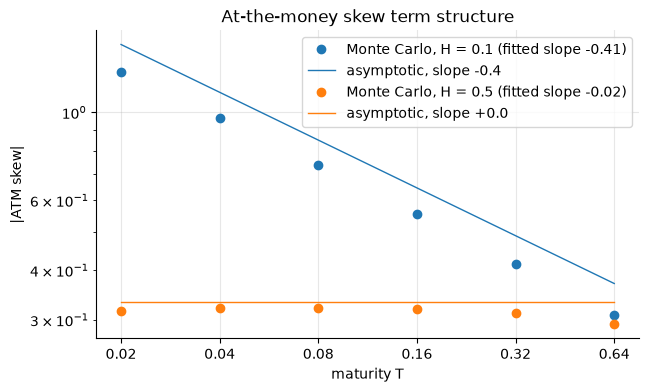

In [17]:
maturities = [0.02, 0.04, 0.08, 0.16, 0.32, 0.64]
steps_per_year = 1000


def atm_skew(params, n_batches=4, n_paths=16_384):
    half_width = 0.1 * np.sqrt(params.xi0 * np.array(maturities))[:, None]   # ± a tenth of a std dev
    strikes = t(np.exp(np.hstack([-half_width, half_width])))                 # shape (n_maturities, 2)
    prices = 0
    for batch in range(n_batches):
        paths = simulate_variance(params, int(max(maturities) * steps_per_year), 1 / steps_per_year,
                                  n_paths, generator=gen(100 + batch))
        prices = prices + mixed_estimator(paths, params.rho, t(maturities), strikes).price / n_batches
    vols = implied_vol(prices, t(1.0), strikes, t(maturities)[:, None], is_call=strikes >= 1.0)
    return ((vols[:, 1] - vols[:, 0]) / (2 * t(half_width[:, 0]))).numpy()


fig, ax = plt.subplots(figsize=(7, 4))
for H, colour in ((0.1, "tab:blue"), (0.5, "tab:orange")):
    params = replace(BASE, hurst=H)
    constant = BASE.rho * BASE.eta * np.sqrt(2 * H) / (2 * (H + 0.5) * (H + 1.5))
    skew = atm_skew(params)
    fitted_slope = np.polyfit(np.log(maturities), np.log(-skew), 1)[0]
    ax.loglog(maturities, -skew, "o", color=colour, label=f"Monte Carlo, H = {H} (fitted slope {fitted_slope:+.2f})")
    ax.loglog(maturities, -constant * np.array(maturities) ** (H - 0.5), "-", color=colour, lw=1,
              label=f"asymptotic, slope {H - 0.5:+.1f}")
ax.set_xticks(maturities, [str(m) for m in maturities])
ax.set_xticks([], minor=True)
ax.set(xlabel="maturity T", ylabel="|ATM skew|", title="At-the-money skew term structure")
ax.legend()
plt.show()

## 2. Deep calibration 

This step takes inspiration by Horvath, Muguruza, Tomas (2021), but with some differences, such as the use of Sobol, and the split in domain/gap/ood.

### Two steps instead of one

Calibration solves $\theta^* = \arg\min_\theta \lVert\sigma_{\text{model}}(\theta) − \sigma_{\text{market}}\rVert$.
The slow part is the map $\theta \mapsto \sigma_{\text{model}}(\theta)$. The paper's proposal:

1. **Offline:** learn the pricing map $\theta \mapsto \sigma_{\text{model}}(\theta)$ with a neural network,
   from surfaces generated by the slow pricer.
2. **Online:** calibrate with a standard optimiser, using the network instead
   of the pricer.

The net takes the four parameters and returns the 80
implied volatilities of the grid. Same input as the Monte Carlo surface computed earlier:

In [18]:
model = VolSurfaceMLP.load(ROOT / "models" / "vol_surface_mlp.pt")
theta = t([BASE.hurst, BASE.eta, BASE.rho, BASE.xi0])

with torch.no_grad():
    nn_surface = model(theta[None])[0].reshape(grid.shape)
    start = time.perf_counter()
    for _ in range(100):                                   # average over many calls: each one is tiny
        model(theta[None])
    nn_seconds = (time.perf_counter() - start) / 100

error = (nn_surface - mc_surface.implied_vol).abs()
print(f"network: {1e3 * nn_seconds:.2f} ms   Monte Carlo: {mc_seconds:.2f} s   "
      f"-> {mc_seconds / nn_seconds:,.0f}x faster")
print(f"max |network − Monte Carlo| = {1e4 * error.max():.1f} bp of vol   "
      f"(Monte Carlo stderr up to {1e4 * mc_surface.implied_vol_stderr.max():.1f} bp)")

network: 0.10 ms   Monte Carlo: 0.53 s   -> 5,094x faster
max |network − Monte Carlo| = 18.1 bp of vol   (Monte Carlo stderr up to 12.6 bp)


### Image-based learning

The network outputs the whole surface on a fixed grid, like the pixels of an
image, rather than one volatility for inputs $(\theta, T, K)$. The output dimension
is larger, but the network exploits the structure across neighbouring points
and the training set needs one Monte Carlo run per sample, shared by all
strikes and maturities.

Below, the network output as an 8 × 10 "image" (left), and the same pixels read as smiles and
compared with Monte Carlo (right).

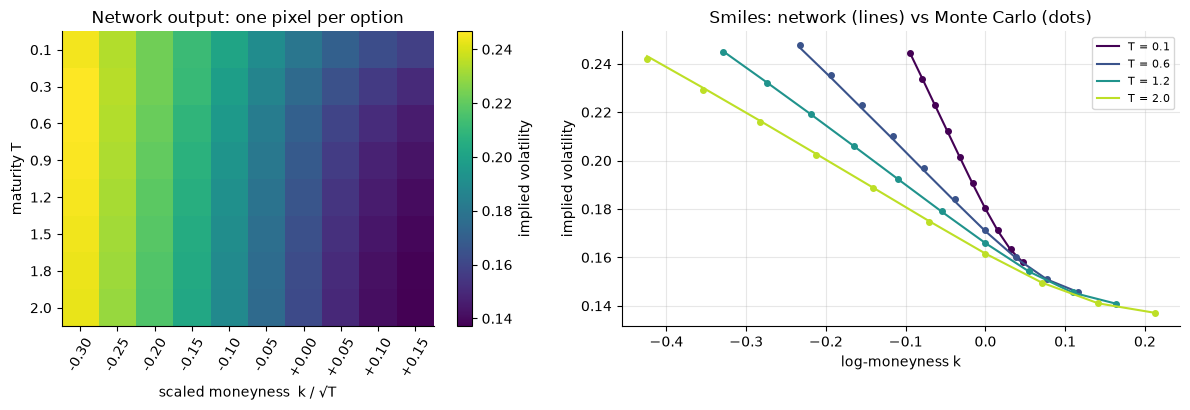

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1, 1.2]})

image = axes[0].imshow(nn_surface, cmap="viridis", aspect="auto")
axes[0].set_xticks(range(grid.shape[1]), [f"{m:+.2f}" for m in grid.scaled_moneyness], rotation=60)
axes[0].set_yticks(range(grid.shape[0]), [str(T) for T in grid.maturities])
axes[0].set(xlabel="scaled moneyness  k / √T", ylabel="maturity T", title="Network output: one pixel per option")
axes[0].grid(False)
fig.colorbar(image, ax=axes[0], label="implied volatility")

colours = plt.cm.viridis(np.linspace(0, 0.9, grid.shape[0]))
for row in (0, 2, 4, 7):
    axes[1].plot(log_k[row], nn_surface[row], "-", color=colours[row], label=f"T = {grid.maturities[row]}")
    axes[1].plot(log_k[row], mc_surface.implied_vol[row], "o", ms=4, color=colours[row])
axes[1].set(xlabel="log-moneyness k", ylabel="implied volatility",
            title="Smiles: network (lines) vs Monte Carlo (dots)")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

### What the approximation can and cannot do

The network is an interpolator of a smooth function on a compact box. Inside
the box, with enough samples, the error is limited by the Monte Carlo noise of
the training labels, and averaging over many noisy samples lets the network do
*better* than any single label. Outside the box nothing constrains it: the
function it has learned is whatever the last layers extrapolate to. Calibration
inherits this: the optimiser will happily return parameters for a surface the
network cannot represent, and only the fit error and the bounds reveal it.

**Inside vs outside the box.** Move one parameter at a time across and beyond its training
range (shaded), keeping the others at `BASE`, and measure the network error against Monte
Carlo over the whole surface. For $H$ the hatched band is the interpolation gap, a range left
out of the training set on purpose.

How to read it: inside the box the error is flat at a few bp, and part of that is the Monte
Carlo noise of the target itself. It rises towards the strongly skewed corner ($\rho \to -1$),
where the surface changes fastest, and jumps as soon as a parameter leaves the box
($H = 0.02$, $\rho \to 0$). The gap leaves no visible mark: filling a hole *between*
training points is easy, leaving the box is not.

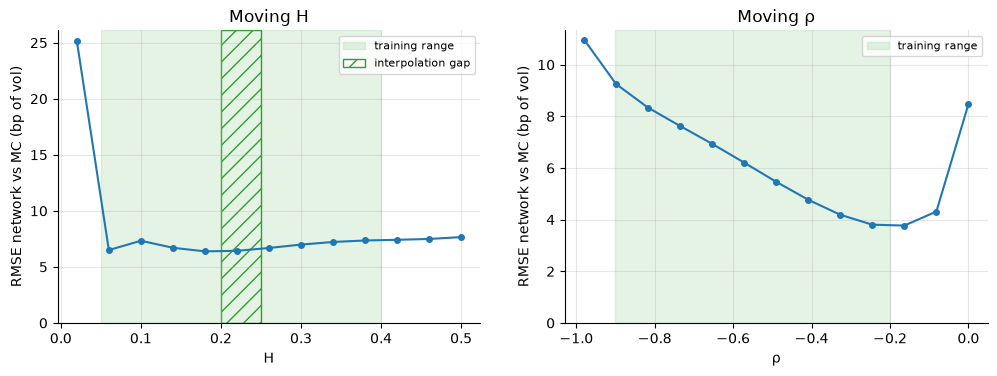

In [21]:
slices = {"hurst": np.linspace(0.02, 0.50, 13), "rho": np.linspace(-0.98, 0.0, 13)}
box_index = {"hurst": 0, "rho": 2}
mc_check = MonteCarloConfig()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, (name, values) in zip(axes, slices.items()):
    rmse = []
    for value in values:
        params = replace(BASE, **{name: float(value)})
        target = implied_vol_surface(params, grid, mc_check, seed=9).implied_vol.flatten()
        with torch.no_grad():
            prediction = model(t([params.hurst, params.eta, params.rho, params.xi0])[None])[0]
        rmse.append(1e4 * torch.sqrt(torch.mean((prediction - target) ** 2)).item())
    i = box_index[name]
    ax.axvspan(TRAIN_BOX.lower[i], TRAIN_BOX.upper[i], color="tab:green", alpha=0.12, label="training range")
    if name == "hurst":
        ax.axvspan(*HURST_GAP, facecolor="none", edgecolor="tab:green", hatch="//", label="interpolation gap")
    ax.plot(values, rmse, "-o", ms=4)
    ax.set(xlabel=labels[name], ylabel="RMSE network vs MC (bp of vol)", title=f"Moving {labels[name]}", ylim=(0, None))
    ax.legend(fontsize=8)
plt.show()

**What calibration sees.** The network is calibrated to two Monte Carlo surfaces: one generated
inside the training box, one with $H = 0.02$, outside it. In the first case the parameters are
recovered. In the second the optimiser still returns an answer: it is stuck on the lower bound
of $H$ and the fit error is larger. Those two signals are the only warnings.

In [22]:
cases = {
    "inside the box": replace(BASE, hurst=0.12, eta=2.2, rho=-0.6, xi0=0.05),
    "outside (H = 0.02)": replace(BASE, hurst=0.02, eta=2.2, rho=-0.6, xi0=0.05),
}
names = ("H", "η", "ρ", "ξ0")
for case, params in cases.items():
    true_theta = np.array([params.hurst, params.eta, params.rho, params.xi0])
    target = implied_vol_surface(params, grid, MonteCarloConfig(), seed=10).implied_vol.flatten().numpy()
    result = calibrate(network_pricer(model), target, TRAIN_BOX)
    print(f"{case}:  RMSE {1e4 * result.rmse:.1f} bp,  {result.n_evaluations} network evaluations")
    for name, true, fitted, at_bound in zip(names, true_theta, result.theta, result.at_bound):
        print(f"    {name:<3} true {true:+.3f}   calibrated {fitted:+.3f}" + ("   <- at bound" if at_bound else ""))

inside the box:  RMSE 5.9 bp,  7 network evaluations
    H   true +0.120   calibrated +0.122
    η   true +2.200   calibrated +2.203
    ρ   true -0.600   calibrated -0.592
    ξ0  true +0.050   calibrated +0.050
outside (H = 0.02):  RMSE 27.6 bp,  12 network evaluations
    H   true +0.020   calibrated +0.050   <- at bound
    η   true +2.200   calibrated +1.810
    ρ   true -0.600   calibrated -0.379
    ξ0  true +0.050   calibrated +0.050
